Дополнительное задание

1. Подзагрузите изображения
2. Сделайте агументацию этих изображений
3. Попробуйте поработать с видеорядом
4. Развлекайтесь :)

1. Загрузим изображения

In [4]:
from PIL import Image
import requests
import sys


def saveImage(img, url, type='jpeg'):
    try:
        img.save(url, type)
    except IOError as e:
        print("Error: Unable to save image.\n")
        sys.exit(1)

def openImage(url, mode):
    try:
        return Image.open(url, mode)
    except IOError as e:
        print("Error: Unable to open image.\n")
        sys.exit(1)


urlTank = 'https://tse4.mm.bing.net/th/id/OIP.dg44V2K9VMT6Lp4UjJiM9gHaE8?rs=1&pid=ImgDetMain&o=7&rm=3'
urlImperialSD = 'https://static.wikia.nocookie.net/starwars/images/c/c8/Imperialattackcruisers.png/revision/latest?cb=20140317112248'

pathPrettyPets = 'D:/MIREA/DPO/Learing/ML_School/Cat_Dog.jpg'

# Скачиваем изображения с сайтов с помощью request

try:
    resp = requests.get(url=urlTank, stream=True).raw
    imgTank = Image.open(resp)
except requests.exceptions.RequestException as e:
    print("Error: Cant dowlnload!\n")
    sys.exit(1)
except IOError as e:
    print("Error: open image file\n")
    sys.exit(1)


try:
    resp = requests.get(urlImperialSD, stream=True).raw
    imgImperialSD = Image.open(resp)
except requests.exceptions.RequestException as e:
    print("Error: Cant download!\n")
    sys.exit(1)
except IOError as e:
    print("Error: open image file\n")
    sys.exit(1)

# Открываем изображение из git-папки

try:
    imgPrettyPets = Image.open(pathPrettyPets)
except IOError as e:
    sys.exit(1)

print("Well Done!\n")

# Сохраним изображения в папку чтобы не скачивать каждый раз :)

saveImage(imgPrettyPets, 'D:/MIREA/DPO/Learing/Practic1_4/PrettyPets.jpg', 'jpeg')
saveImage(imgImperialSD, 'D:/MIREA/DPO/Learing/Practic1_4/ISD.jpg', 'jpeg')
saveImage(imgTank, 'D:/MIREA/DPO/Learing/Practic1_4/Tank.jpg', 'jpeg')

Well Done!



In [5]:
import time

imgImperialSD = openImage('D:/MIREA/DPO/Learing/Practic1_4/ISD.jpg', 'r')

imgPrettyPets.show()
imgImperialSD.show()
imgTank.show()

# time.sleep(10)

# imgPrettyPets.close()
# imgImperialSD.close()
# imgTank.close()
# Только для ОКОНЧАТЕЛЬНО конца работы с изображением :)

2. Аугментация изображений

In [6]:
# Посмотрим на информацию в изображениях

print(f'Data about ISD: {imgImperialSD._getexif()}')
print(f'Data about Tank: {imgTank._getexif()}')
print(f'Data about PrettyPets: {imgPrettyPets._getexif()}')

Data about ISD: None
Data about Tank: None
Data about PrettyPets: {296: 2, 34665: 220, 305: 'Adobe Photoshop CS6 (Windows)', 274: 1, 306: '2018-01-29T17:45:52-05:00', 33432: 'This content is subject to copyright.', 282: 300.0, 283: 300.0, 36864: b'0220', 40962: 2000, 40963: 1451}


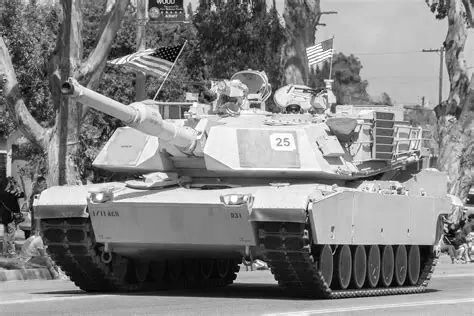

In [7]:
# Разделим изображение на "каналы"

r, g, b = imgTank.split()

r

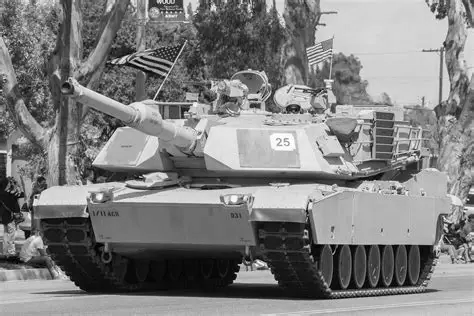

In [8]:
g

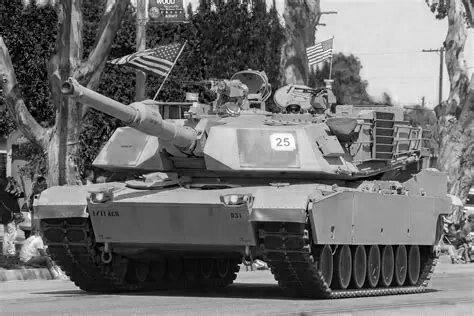

In [9]:
b

Width: 2000
Height: 1451


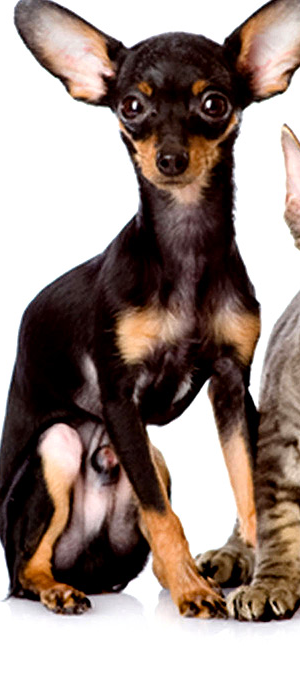

In [10]:
# Дальше будем работать с PrettyPets

print(f'Width: {imgPrettyPets.width}\nHeight: {imgPrettyPets.height}')

imgPrettyPetsCropped = imgPrettyPets.crop((170, 400, 470, 1100))

saveImage(imgPrettyPetsCropped, 'D:/MIREA/DPO/Learing/Practic1_4/PrettyPetsCropped.jpg')

imgPrettyPetsCropped

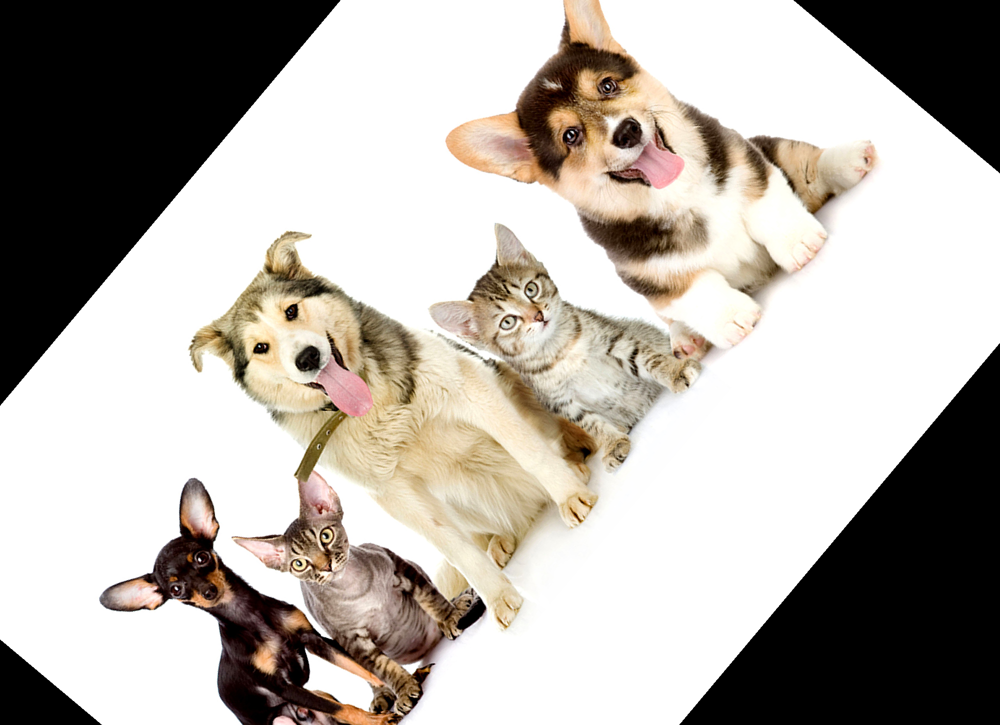

In [11]:
imgPrettyPetsRotate = imgPrettyPets.rotate(50, center=(1050, 790))
imgPrettyPetsRotate

In [12]:
# Попробуем изменить изображения

import matplotlib.pyplot as plt
import cv2


frame = cv2.imread('D:/MIREA/DPO/Learing/Practic1_4/PrettyPets.jpg')
frame.shape

(1451, 2000, 3)

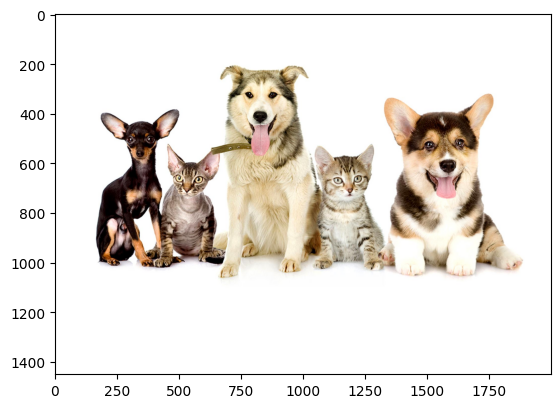

In [13]:
frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

plt.imshow(frame)
plt.show()

Original shape: (2000, 1451)
New shape: (2000, 1451)


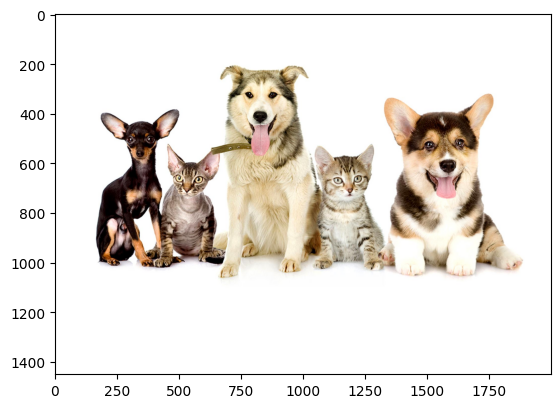

In [14]:
# Через 1

def scopeValue(value, scope):
    return int(value * scope)

height, width, extent = frame.shape

newHeight, newWidth = 0, 0

while 1:
    scope = float(input('Inter new scope > '))
    newWidth = scopeValue(width, scope)
    newHeight = scopeValue(height, scope)
    if (scope > 0) and (newHeight > 0) and (newWidth > 0):
        break
    else:
        print('Try again, bad scope.\n')

dim = (newWidth, newHeight)
print(f'Original shape: {(width, height)}')
print(f'New shape: {dim}')

resizedFrame = cv2.resize(frame, dim, interpolation=cv2.INTER_AREA)

plt.imshow(resizedFrame)
plt.show()

In [15]:
# Сделаем сразу, чтобы просмотреть результаты разных интерполяций и сравнить время (но для малого кол-ва значений)

interpolationTypesCV2 = {
    'NEAREST': cv2.INTER_NEAREST,
    'LINEAR': cv2.INTER_LINEAR,
    'LEXACT': cv2.INTER_LINEAR_EXACT,
    'CUBIC': cv2.INTER_CUBIC,
    'LANCZOS4': cv2.INTER_LANCZOS4,
    'AREA': cv2.INTER_AREA
}

interpolationTypesPillow = {
    'NEAREST': Image.Resampling.NEAREST,
    'LINEAR': Image.Resampling.BILINEAR,
    'CUBIC': Image.Resampling.BICUBIC,
    'LANCZOS4': Image.Resampling.LANCZOS,
    'HAMMING': Image.Resampling.HAMMING
}

In [16]:
def resizeWithCV2All(img, ratio, isPlot=True, fileName=None):
    width, height, dir = img.shape
    print(f'Original shape: {(width, height)}')
    dim = (scopeValue(height, ratio), scopeValue(width, ratio))
    print(f'New shape: {dim}')

    imgs = [None for i in range(len(interpolationTypesCV2))]
    times = [0.0 for i in range(len(interpolationTypesCV2))]
    for i in range(len(interpolationTypesCV2)):
        timeStart = time.time()
        for j in range(10):
            imgResized = cv2.resize(img, dim, interpolation=( list(interpolationTypesCV2.items())[i][1] ))
        times[i] = time.time() - timeStart
        imgs[i] = imgResized

    if isPlot:
        # plt.figure(figsize=(len(imgs) + 1, 1), dpi=1000)
        # plt.subplot(1, len(imgs) + 1, 1) 
        # Фигня какая-то
        plt.figure(1, ((len(interpolationTypesCV2) + 1) * 4, 4))
        plt.subplot(1, len(interpolationTypesCV2) + 1, 1)
        plt.title(f'ORIG {ratio}')
        plt.imshow(img)
        # plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.axis('off')
        for i in range(len(imgs)):
            plt.subplot(1, len(imgs) + 1, i + 2)
            plt.title(list(interpolationTypesCV2.items())[i][0])
            plt.imshow(imgs[i])
            # plt.imshow(cv2.cvtColor(imgs[i], cv2.COLOR_BGR2RGB))
            plt.axis('off')
        plt.subplots_adjust(wspace=0)
        if fileName != None:
            plt.savefig(fileName)
        plt.show()

    return imgs, times

In [17]:
def resizeWithPillowAll(img, scope, isPlot=True, fileName=None):
    width, height = img.size
    newWidth, newHeight = scopeValue(width, scope), scopeValue(height, scope)
    imgs = [None for i in range(len(interpolationTypesPillow))]
    times = [0.0 for i in range(len(interpolationTypesPillow))]

    for i in range(len(interpolationTypesPillow)):
        startTime = time.time()
        for j in range(10):
            imgResized = img.resize((newWidth, newHeight), list(interpolationTypesPillow.items())[i][1])
        times[i] = time.time() - startTime
        imgs[i] = imgResized

    if isPlot:
        plt.figure(1, ((len(interpolationTypesPillow) + 1) * 4, 4))
        plt.subplot(1, len(interpolationTypesPillow) + 1, 1)
        plt.title(f'ORIG {scope}x')
        plt.imshow(img)
        plt.axis('off')
        for i in range(len(imgs)):
            plt.subplot(1, len(interpolationTypesPillow) + 1, i + 2)
            plt.title(list(interpolationTypesPillow.items())[i][0])
            plt.imshow(imgs[i])
            plt.axis('off')
        plt.subplots_adjust(wspace=0)
        if fileName != None:
            plt.savefig(fileName)
        plt.show()

    return imgs, times

In [18]:
def screenTimes(times, interpolationTypes):
    plt.bar(list(interpolationTypes.keys()), times)
    plt.show()

Original shape: (1729, 1496)
New shape: (74, 86)


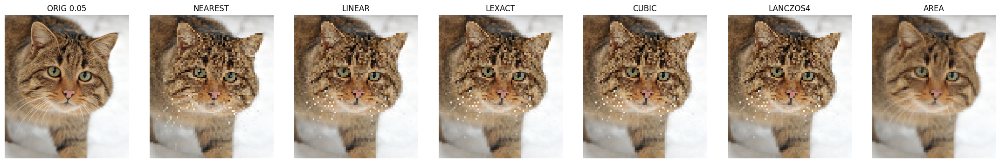

Original shape: (1729, 1496)
New shape: (187, 216)


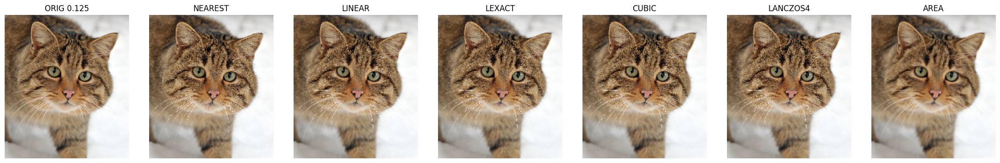

Original shape: (1729, 1496)
New shape: (374, 432)


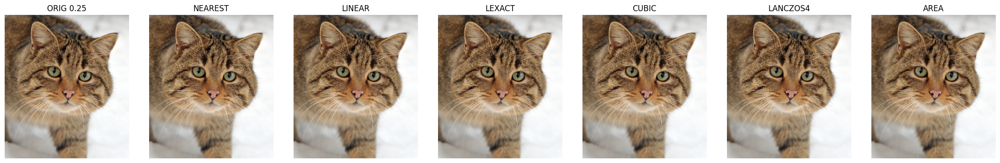

Original shape: (1729, 1496)
New shape: (748, 864)


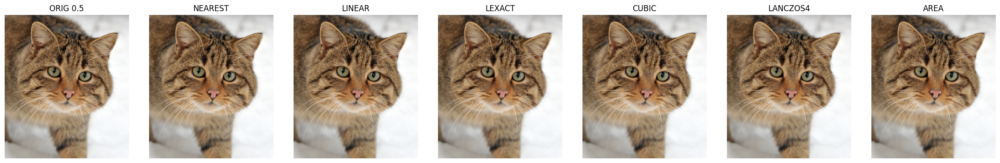

Original shape: (1729, 1496)
New shape: (1870, 2161)


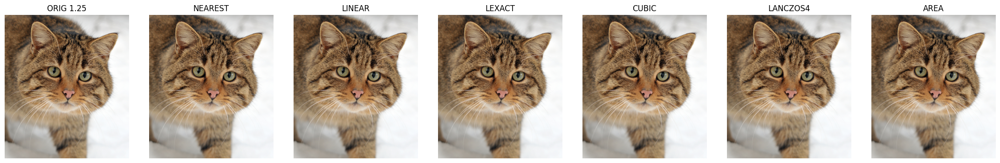

Original shape: (1729, 1496)
New shape: (2992, 3458)


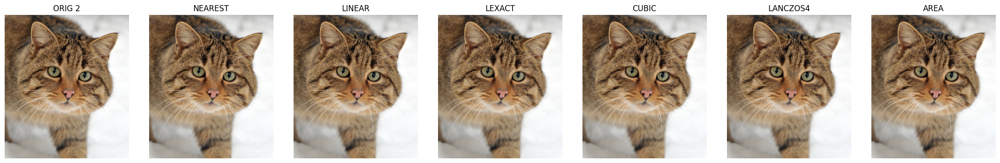

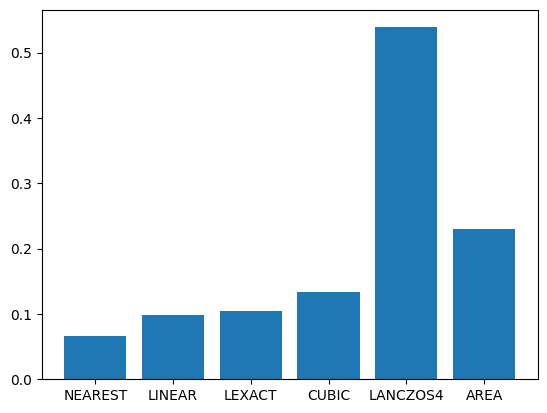

In [19]:
    
testImage = cv2.imread('D:/MIREA/DPO/Learing/Practic1_4/LookingCat.jpg')
testImage = cv2.cvtColor(testImage, cv2.COLOR_BGR2RGB)
times = [0.0 for i in range(len(interpolationTypesCV2))]
for scope in [0.05, 0.125, 0.25, 0.5, 1.25, 2]:
    partTime = resizeWithCV2All(testImage, scope)[1]
    times = [x + y for x, y in zip(times, partTime)]
screenTimes(times, interpolationTypesCV2)

Original size: (1496, 1729)


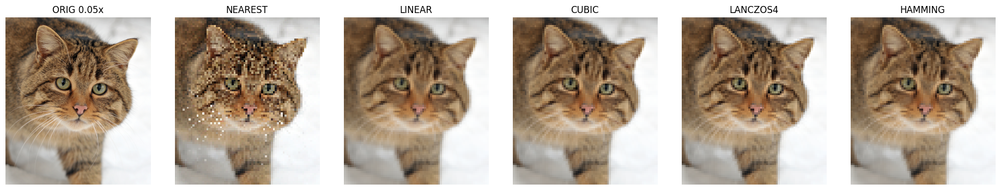

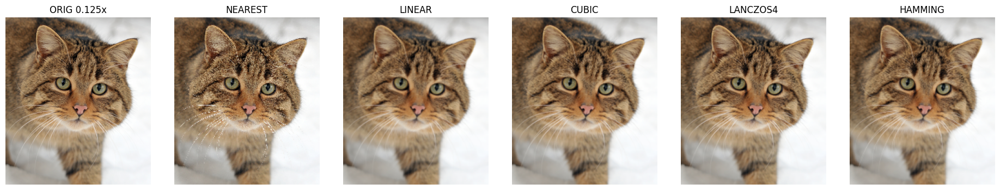

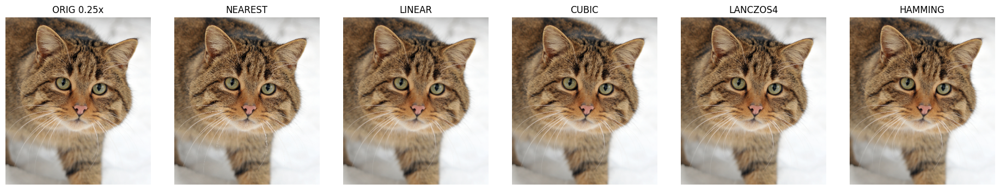

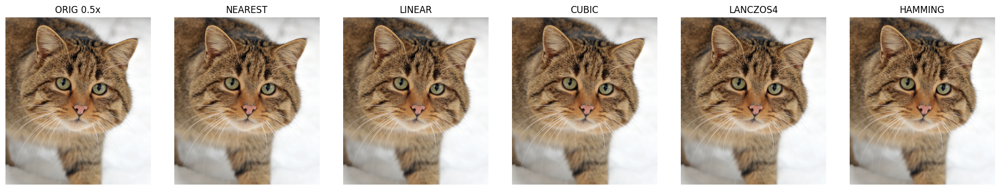

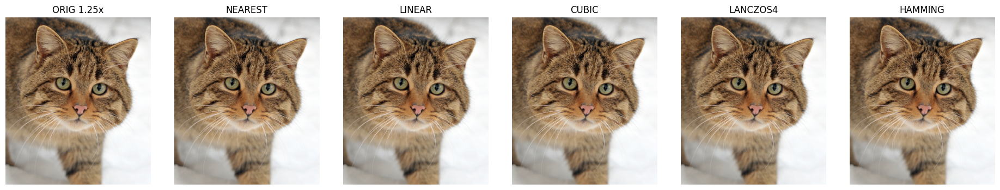

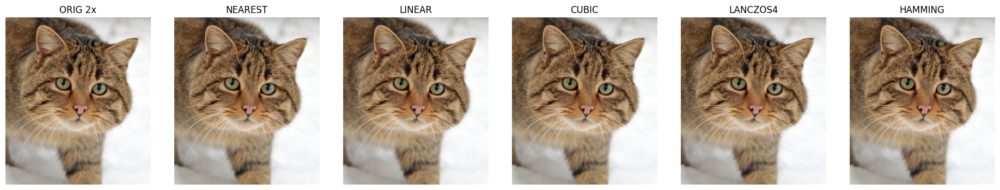

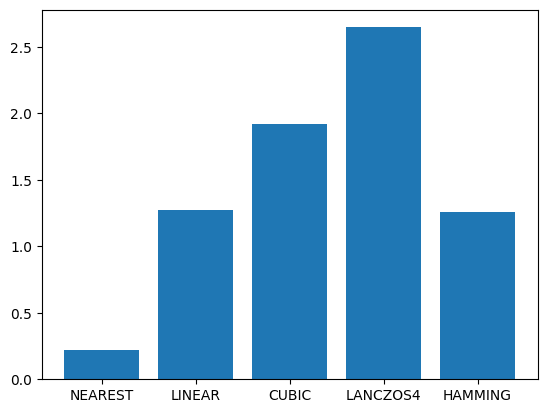

In [20]:
testImage = Image.open('D:/MIREA/DPO/Learing/Practic1_4/LookingCat.jpg')
print(f'Original size: {testImage.size}')
times = [0.0 for i in range(len(interpolationTypesPillow))]
for scope in [0.05, 0.125, 0.25, 0.5, 1.25, 2]:
    partTime = resizeWithPillowAll(testImage, scope)[1]
    times = [x + y for x, y in zip(times, partTime)]
screenTimes(times, interpolationTypesPillow)

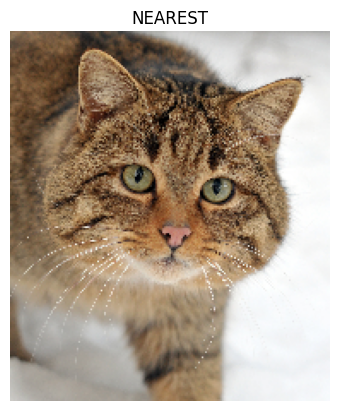

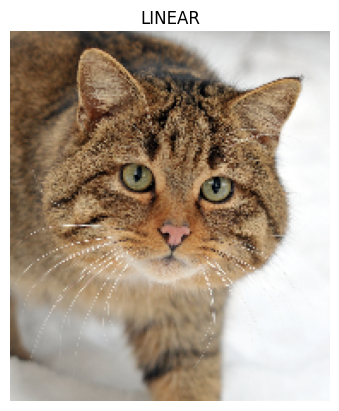

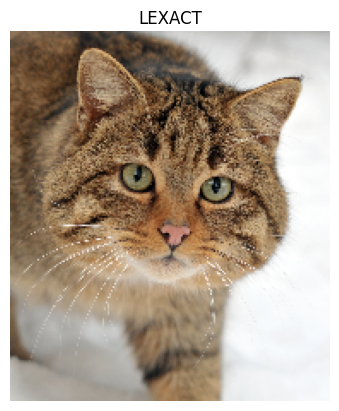

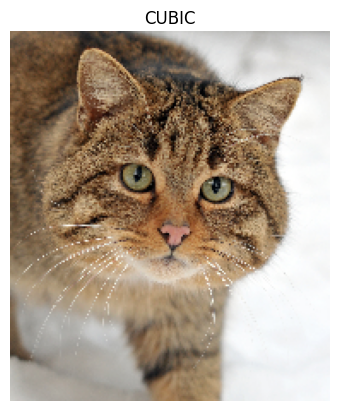

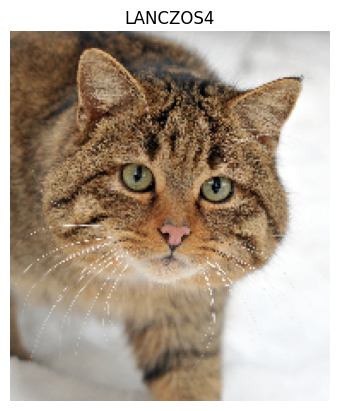

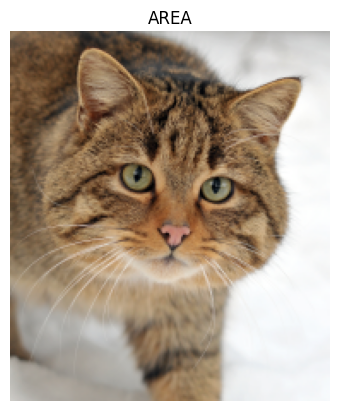

In [21]:
# Проверяю cv2, не нравиться, что фигня выводиться (на моё мнение) -- да, всё фигово, качества 0, но скорость большая )))))

imgTest = cv2.imread('D:/MIREA/DPO/Learing/Practic1_4/LookingCat.jpg')
imgTest = cv2.cvtColor(imgTest, cv2.COLOR_BGR2RGB)
width, height, dim = imgTest.shape
width, height = scopeValue(imgTest.shape[1], 0.125), scopeValue(imgTest.shape[0], 0.125)
for i in range(len(interpolationTypesCV2)):
    imgWork = imgTest.copy()
    plt.title(f'{list(interpolationTypesCV2.items())[i][0]}')
    plt.axis('off')
    plt.imshow(cv2.resize(imgWork, (width, height), interpolation=list(interpolationTypesCV2.items())[i][1]))
    plt.show()

Работаем с видео

In [11]:
import cv2

capture = cv2.VideoCapture(0)

while 1:
    rep, frame = capture.read()
    if rep == True:
        cv2.imshow('frame', frame)
        cv2.waitKey(1)
        if cv2.getWindowProperty('frame', cv2.WND_PROP_VISIBLE) < 1:        
            break
    else:
        break
    
capture.release()
cv2.destroyAllWindows()

In [35]:
from skimage.metrics import structural_similarity as ssim
import sys

def calcDifference(img1, img2):
    score, diff = ssim(img1, img2, full=True)
    diff = (diff * 255).astype('uint8')
    return diff, score

video = cv2.VideoCapture(0)

if (video.isOpened() == False):
    print('Unable to open video.\n')
    sys.exit()

ret, frame = video.read()

if (ret == False):
    print('Unable to read frame.\n')
    sys.exit()

oldFrame = cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY)
cv2.imshow('Frame changing :)', oldFrame)
cv2.waitKey(1)

while 1:
    ret, frame = video.read()

    if ret == True:
        frame = cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY)
        diff, score = calcDifference(frame, oldFrame)
        cv2.imshow('Frame changing :)', diff)
        cv2.waitKey(1)

        if cv2.getWindowProperty('Frame changing :)', cv2.WND_PROP_VISIBLE) < 1:        
            break
        oldFrame = frame.copy()
    else:
        print('Unable to read frame.\n')
        sys.exit() 

video.release()
cv2.destroyAllWindows()